# Рекомендательные системы МФТИ Осень 2026 — домашнее задание 1

Датасет — [Avito ML Cup 2025](https://ods.ai/competitions/avitotechmlchallenge2025), скачиваем его с [зеркала на Kaggle](https://www.kaggle.com/datasets/sharthz23/avito-cup-2025-recsys).

Из датасета используем три таблицы: `clickstream` (действия пользователей), `events` (справочник типов событий) и `cat_features` (признаки объявлений). Подробно сущности и поля описаны в разделе 1.

**Что рекомендуем.** Группы товаров (`node`). Объявления живут недолго, а группы стабильны, поэтому рекомендовать удобнее их.

**Что считаем релевантным.** Группу, по которой пользователь хотя бы раз связался с продавцом. Просмотр без контакта считаем нерелевантным.

In [4]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
from scipy.sparse import csr_matrix

from models.als import ImplicitALS
from models.custom_target_als import CustomTargetALS
from models.ease import EASE
from models.fm import FMRecommender
from models.item_knn import ImplicitItemKNN
from models.recommend import RecommenderMixin

SEED = 42
np.random.seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)

## 1. Данные

### Сущности и поля

Все идентификаторы в датасете анонимизированы: вместо названий товаров, категорий, городов и типов событий — числа.

**Пользователь** — `cookie`. Анонимный идентификатор браузера или устройства, а не аккаунт: один человек с телефона и с ноутбука даст два разных `cookie`. Других данных о пользователе (пол, возраст, город) нет, поэтому признаков пользователя у моделей нет — только история действий.

**Объявление** — `item`. Конкретное объявление конкретного продавца. Объявления живут недолго: их продают и снимают, на их место приходят новые.

**Группа товаров** — `node`. Объединение похожих объявлений, разметку сделали организаторы. Каждое объявление лежит ровно в одной группе (проверено ниже), а в одной группе может быть от одного до сотен тысяч объявлений разных продавцов. Названий у групп нет, поэтому что именно в них лежит (например, конкретная модель телефона или вид товара), по данным сказать нельзя.

**Категория** — `category`. Верхний уровень каталога. Каждая группа лежит ровно в одной категории, так что получается строгая иерархия: объявление → группа → категория.

**Локация** — `location`. Регион, где размещено объявление.

**Параметры объявления** — `clean_params`. Список пар «атрибут – значение», тоже числами. Набор атрибутов свой в каждой категории, и сводить их на уровень группы сложно, поэтому в работе не используем.

**Событие** — строка `clickstream`: пользователь `cookie` сделал действие типа `event` с объявлением `item` в момент `event_date` (точность до секунды). Поля `platform` и `surface` (платформа и место на сайте или в приложении, где было действие) в работе не используем.

**Тип события и контакт** — справочник `events`. В нём только номер типа и флаг `is_contact`. Контакт — целевое действие: пользователь выходит на связь с продавцом (по описанию соревнования — звонок, сообщение и т. п.). Какой номер какому действию соответствует, организаторы не раскрывают.

### Как сущности превращаются в данные для моделей

`prepare_data.py` переходит от событий с объявлениями к **парам пользователь – группа**:

| поле в `interactions.parquet` | откуда берётся |
|---|---|
| `user_id` | `cookie` |
| `item_id` | `node`, **это группа, а не объявление** |
| `timestamp` | время последнего события пары |
| `contact` | 1, если среди событий пары был хотя бы один контакт |

| поле в `item_metadata.parquet` | откуда берётся |
|---|---|
| `item_id` | `node` |
| `category` | категория группы |
| `location` | самая частая локация среди объявлений группы |
| `listing_count` | сколько объявлений в группе |

Дальше в ноутбуке «объект» (`item`) везде означает группу товаров. Рекомендуем группы, потому что объявления живут недолго и по отдельному объявлению почти нет истории, а группа стабильна и копит взаимодействия многих пользователей.

In [5]:
clickstream = "read_parquet('data/raw/avito/clickstream.pq')"
cat_features = "read_parquet('data/raw/avito/cat_features.pq')"
events_ref = "read_parquet('data/raw/avito/events.pq')"

# размер каталога и проверка иерархии объявление -> группа -> категория
hierarchy = duckdb.sql(f'''
    SELECT
        COUNT(DISTINCT item) AS items,
        COUNT(DISTINCT node) AS groups,
        COUNT(DISTINCT category) AS categories,
        COUNT(DISTINCT location) AS locations,
        (SELECT COUNT(*) FROM (SELECT item FROM {cat_features} GROUP BY item HAVING COUNT(DISTINCT node) > 1)) AS items_in_several_groups,
        (SELECT COUNT(*) FROM (SELECT node FROM {cat_features} GROUP BY node HAVING COUNT(DISTINCT category) > 1)) AS groups_in_several_categories
    FROM {cat_features}
''').df()

# типы событий в подвыборке и какие из них считаются контактом
event_types = duckdb.sql(f'''
    SELECT e.event, e.is_contact, COUNT(c.event) AS events
    FROM {events_ref} e
    LEFT JOIN (SELECT event FROM {clickstream} WHERE cookie % 32 = 0) c USING (event)
    GROUP BY e.event, e.is_contact
    ORDER BY e.is_contact DESC, events DESC
''').df()
event_types["share"] = (event_types["events"] / event_types["events"].sum()).round(4)

display(hierarchy, event_types)
print("доля контактных событий:", round(event_types.loc[event_types["is_contact"] == 1, "events"].sum() / event_types["events"].sum(), 4))

,items,groups,categories,locations,items_in_several_groups,groups_in_several_categories
0,22646691,408474,52,4822,0,0


,event,is_contact,events,share
0,10,1,26899,0.0128
1,15,1,10698,0.0051
2,5,1,9552,0.0046
3,19,1,6036,0.0029
4,4,1,4928,0.0023
5,13,1,3443,0.0016
6,14,1,1531,0.0007
7,2,1,328,0.0002
8,0,1,215,0.0001
9,1,1,5,0.0000


доля контактных событий: 0.0303


Иерархия строгая: ни одно объявление не попадает в две группы, ни одна группа — в две категории. Из 19 типов событий контактом считаются 13, но почти все события — один неконтактный тип (17, судя по объёму — просмотр). На контакты приходится около 3 % событий, а после агрегации в пары — 6,8 % пар.

### Загрузка и очистка

После запуска `prepare_data.py` уже собраны пары пользователь–группа: несколько событий одной пары объединены в одну строку, время пары — время последнего события, `contact = 1`, если хотя бы одно событие было контактом. Здесь переводим контакт в рейтинг (контакт → 5, без контакта → 0) и ещё раз проверяем 10-core.

In [6]:
interactions = pd.read_parquet("data/processed/avito/interactions.parquet")
item_metadata = pd.read_parquet("data/processed/avito/item_metadata.parquet")

interactions["rating"] = interactions["contact"] * 5.0
interactions = interactions[["user_id", "item_id", "rating", "timestamp"]]

# итеративный 10-core: у каждого пользователя и каждой группы должно быть хотя бы 10 пар
while True:
    user_n = interactions["user_id"].map(interactions["user_id"].value_counts())
    item_n = interactions["item_id"].map(interactions["item_id"].value_counts())
    keep = (user_n >= 10) & (item_n >= 10)
    if keep.all():
        break
    interactions = interactions[keep]

print("пар:", len(interactions))
print("пользователей:", interactions["user_id"].nunique())
print("групп:", interactions["item_id"].nunique())
print("контактов:", int((interactions["rating"] >= 4).sum()))

пар: 288964
пользователей: 3443
групп: 6536
контактов: 19734


## 2. EDA

### Объём и качество данных

Посмотрим, сколько данных остаётся на каждом шаге отбора, и проверяем исходные события на пропуски и дубликаты.

In [7]:
clickstream = "read_parquet('data/raw/avito/clickstream.pq')"
pairs = "read_parquet('data/processed/avito/interactions_sample.parquet')"
core = "read_parquet('data/processed/avito/interactions.parquet')"

volume = duckdb.sql(f'''
    SELECT 1 AS step, 'все события' AS stage, COUNT(*) AS rows, COUNT(DISTINCT cookie) AS users, COUNT(DISTINCT node) AS items FROM {clickstream}
    UNION ALL SELECT 2, 'события cookie % 32 = 0', COUNT(*), COUNT(DISTINCT cookie), COUNT(DISTINCT node) FROM {clickstream} WHERE cookie % 32 = 0
    UNION ALL SELECT 3, 'пары пользователь-группа', COUNT(*), COUNT(DISTINCT user_id), COUNT(DISTINCT item_id) FROM {pairs}
    UNION ALL SELECT 4, 'после 10-core', COUNT(*), COUNT(DISTINCT user_id), COUNT(DISTINCT item_id) FROM {core}
    ORDER BY step
''').df()

quality = duckdb.sql(f'''
    SELECT MIN(event_date) AS first_event, MAX(event_date) AS last_event,
           COUNT(*) - COUNT(cookie) AS missing_cookie, COUNT(*) - COUNT(node) AS missing_node,
           COUNT(*) - COUNT(event_date) AS missing_date,
           COUNT(*) - COUNT(DISTINCT (cookie, item, event, event_date)) AS duplicates
    FROM {clickstream} WHERE cookie % 32 = 0
''').df()

display(volume, quality)

,step,stage,rows,users,items
0,1,все события,68806152,134294,408474
1,2,события cookie % 32 = 0,2098778,4202,106770
2,3,пары пользователь-группа,475100,4202,106770
3,4,после 10-core,288964,3443,6536


,first_event,last_event,missing_cookie,missing_node,missing_date,duplicates
0,2025-01-10 00:00:03,2025-02-23,0,0,0,13492


Исходный `clickstream` — 68,8 млн событий от 134 тыс. пользователей по 408 тыс. группам товаров, с 10 января по 23 февраля 2025 года. Для экспериментов берём каждого 32-го пользователя (`cookie % 32 == 0`). Отбор не зависит от поведения пользователя, так что подвыборка воспроизводима и не смещает распределения.

Пропусков в ключевых полях нет. Полных дубликатов (тот же пользователь, объявление, событие и время) 13,5 тыс. из 2,1 млн — меньше 1 %, и они всё равно схлопываются при агрегации в пары. После агрегации 2,1 млн событий превращаются в 475 тыс. пар пользователь–группа.

10-core сильнее всего режет группы: 106 770 → 6 536. У большинства групп в подвыборке всего несколько событий, и выучить для них что-то осмысленное нельзя. Пользователей остаётся 3 443 из 4 202, пар — 289 тыс.

In [8]:
is_contact = interactions["rating"] >= 4
user_counts = interactions["user_id"].value_counts()
item_counts = interactions["item_id"].value_counts()
contacts_per_user = is_contact.groupby(interactions["user_id"]).sum()
contacts_per_item = is_contact.groupby(interactions["item_id"]).sum()

pd.Series({
    "плотность матрицы": len(interactions) / (len(user_counts) * len(item_counts)),
    "доля контактов среди пар": is_contact.mean(),
    "пользователей хотя бы с одним контактом": (contacts_per_user > 0).mean(),
    "групп хотя бы с одним контактом": (contacts_per_item > 0).mean(),
    "медиана пар на пользователя": user_counts.median(),
    "медиана пар на группу": item_counts.median(),
    "доля пар у топ-1% групп": item_counts.head(len(item_counts) // 100).sum() / len(interactions),
    "доля пар у топ-10% групп": item_counts.head(len(item_counts) // 10).sum() / len(interactions),
}).round(3)

плотность матрицы                           0.013
доля контактов среди пар                    0.068
пользователей хотя бы с одним контактом     0.860
групп хотя бы с одним контактом             0.644
медиана пар на пользователя                58.000
медиана пар на группу                      20.000
доля пар у топ-1% групп                     0.129
доля пар у топ-10% групп                    0.478
dtype: float64

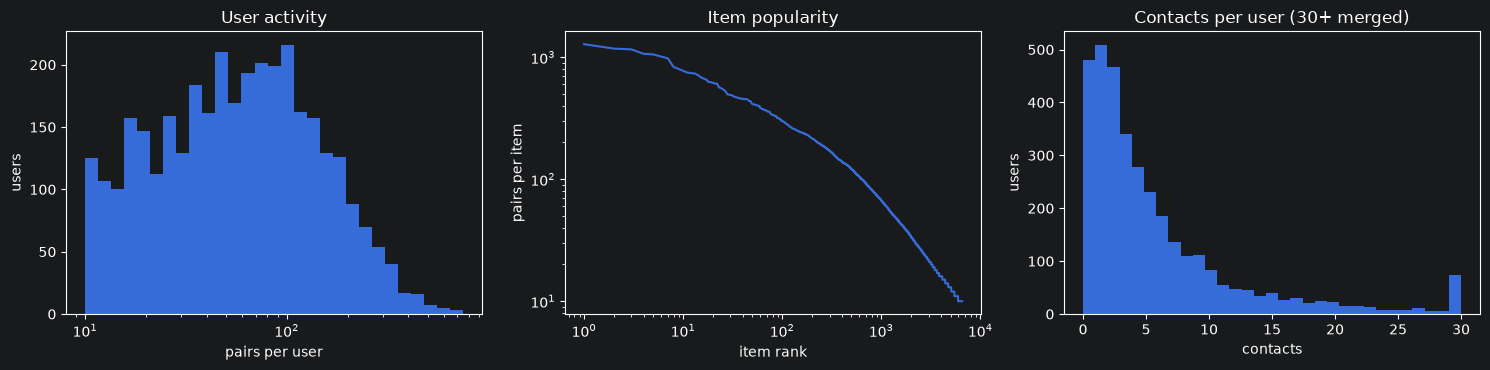

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

axes[0].hist(user_counts, bins=np.logspace(1, np.log10(user_counts.max()), 30))
axes[0].set(xscale="log", title="User activity", xlabel="pairs per user", ylabel="users")

axes[1].loglog(np.arange(1, len(item_counts) + 1), item_counts.to_numpy())
axes[1].set(title="Item popularity", xlabel="item rank", ylabel="pairs per item")

axes[2].hist(contacts_per_user.clip(upper=30), bins=31)
axes[2].set(title="Contacts per user (30+ merged)", xlabel="contacts", ylabel="users")

plt.tight_layout()

- Плотность матрицы 1,3 %, то есть данные очень разреженные.
- У медианного пользователя 58 групп, распределение активности с длинным хвостом.
- Популярность групп тоже с длинным хвостом: на 1 % самых популярных групп приходится 13 % пар, на 10 % — почти половина. Popularity здесь будет неплохим бейзлайном.
- Контакты редкие: 6,8 % пар. У 14 % пользователей контактов нет вообще. Модели учатся только на контактах, поэтому матрица $P$ ещё в 15 раз разреженнее, чем матрица всех действий.

### Время

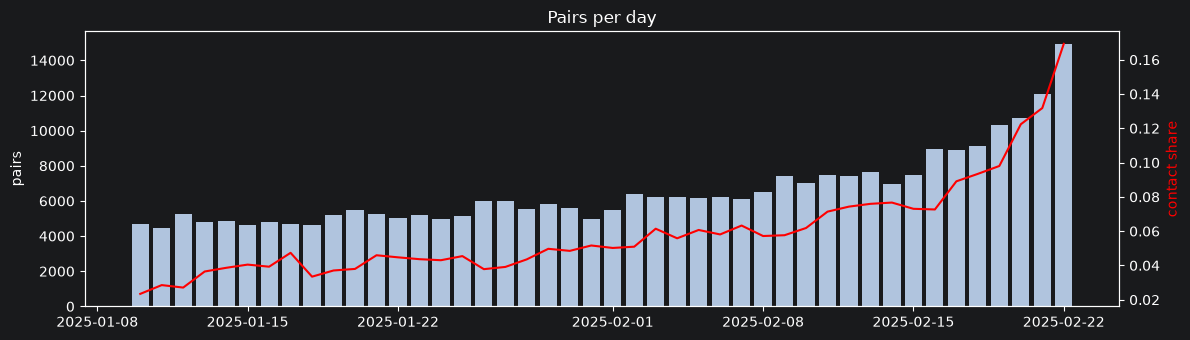

In [10]:
daily = interactions.groupby(interactions["timestamp"].dt.date)["rating"].agg(
    pairs="size", contact_share=lambda r: (r >= 4).mean()
)
daily = daily[daily["pairs"] >= 100]

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(daily.index, daily["pairs"], color="lightsteelblue")
ax.set(title="Pairs per day", ylabel="pairs")
ax2 = ax.twinx()
ax2.plot(daily.index, daily["contact_share"], color="red")
ax2.set_ylabel("contact share", color="red")
plt.tight_layout()

Данные покрывают примерно полтора месяца. Пар в день стабильно около 6 тыс., доля контактов держится в районе 4–7 %, резких сдвигов нет. Поэтому используем временное разбиение leave-last-out (подробнее в разделе 3).

### Метаданные

категорий: 51
локаций: 138
доля пар в самой частой локации: 0.832
доля пар в топ-10 категориях: 0.732


,min_listings,max_listings,pairs,contact_share
listing_bin,,,,
0,1,267,19452,0.035935
1,268,516,21729,0.047218
2,517,945,27895,0.052375
3,946,2402,47580,0.059962
4,2404,463451,172308,0.079480


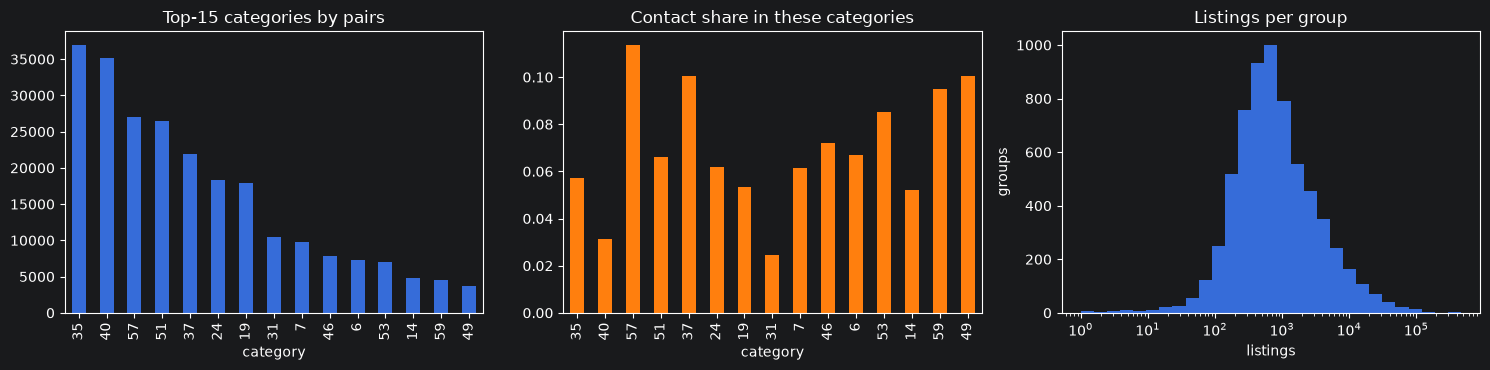

In [11]:
items = item_metadata[item_metadata["item_id"].isin(item_counts.index)].copy()
items["listing_bin"] = pd.qcut(items["listing_count"], 5, labels=False, duplicates="drop")
events = interactions.merge(items, on="item_id")
contact_share = lambda r: (r >= 4).mean()

top_categories = events.groupby("category")["rating"].agg(pairs="size", contact_share=contact_share).nlargest(15, "pairs")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
top_categories["pairs"].plot.bar(ax=axes[0], title="Top-15 categories by pairs")
top_categories["contact_share"].plot.bar(ax=axes[1], color="tab:orange", title="Contact share in these categories")
axes[2].hist(items["listing_count"], bins=np.logspace(0, np.log10(items["listing_count"].max()), 30))
axes[2].set(xscale="log", title="Listings per group", xlabel="listings", ylabel="groups")
plt.tight_layout()

print("категорий:", items["category"].nunique())
print("локаций:", items["location"].nunique())
print("доля пар в самой частой локации:", round(events["location"].value_counts(normalize=True).iloc[0], 3))
print("доля пар в топ-10 категориях:", round(events["category"].value_counts(normalize=True).head(10).sum(), 3))

events.groupby("listing_bin").agg(
    min_listings=("listing_count", "min"), max_listings=("listing_count", "max"),
    pairs=("rating", "size"), contact_share=("rating", contact_share),
)

- 51 категория и 138 локаций.
- На топ-10 категорий приходится 73 % пар, а доля контактов между крупными категориями отличается в разы. Категория должна помогать FM.
- Локация почти константна: 83 % пар в одной локации. Признак слабый.
- Число объявлений в группе сильно скошено (от 1 до 463 тыс.), поэтому бьём его на 5 квантильных корзин. Доля контактов растёт от первой корзины к последней: 3,6 % → 7,9 %. В крупных группах контактов больше.

## 3. Протокол оценки

**Разбиение.** Временное leave-last-out: для каждого пользователя последняя по времени пара идёт в test, предпоследняя — в validation, остальное — в train. Модель всегда предсказывает будущее по прошлому.

**Кому считаем метрики.** Только тем пользователям, у которых целевая пара — контакт: если пользователь просто посмотрел группу, правильного ответа нет. У каждого такого пользователя ровно один релевантный объект.

**Кандидаты.** Все группы из train, кроме тех, что пользователь уже видел (вся его история, а не только контакты). Видели — значит, рекомендовать повторно не нужно.

**Новые пользователи и объекты.** После 10-core у каждого пользователя минимум 10 пар, так что в train он точно есть. Группы, которых нет в train, модель не может порекомендовать, поэтому такие целевые пары из оценки исключаем (сколько их — видно ниже).

**Подбор и финальный запуск.** Гиперпараметры подбираем на validation, обучая модели на train. Потом обучаем модель с лучшими параметрами на train + validation и один раз считаем test. Протокол одинаковый для всех моделей.

**Метрики.** Основная метрика — **NDCG@10**, выбрана до подбора: она учитывает, на какой позиции стоит правильная группа, а пользователь видит верх выдачи. Дополнительная — **Recall@10** (HitRate@10, потому что релевантный объект один): попала ли группа, где был контакт, в top-10 вообще.

$$\text{Recall@10} = \mathbb{1}[\text{rank} \le 10], \qquad \text{NDCG@10} = \frac{\mathbb{1}[\text{rank} \le 10]}{\log_2(\text{rank} + 1)}$$

In [12]:
interactions = interactions.sort_values(["user_id", "timestamp", "item_id"])
from_end = interactions.groupby("user_id").cumcount(ascending=False)
train = interactions[from_end >= 2].copy()
val = interactions[from_end == 1].copy()
test = interactions[from_end == 0].copy()

# индексы строим только по train
user_index = {u: i for i, u in enumerate(sorted(train["user_id"].unique()))}
item_index = {it: i for i, it in enumerate(sorted(train["item_id"].unique()))}
for df in (train, val, test):
    df["user_idx"] = df["user_id"].map(user_index)
    df["item_idx"] = df["item_id"].map(item_index)
n_users, n_items = len(user_index), len(item_index)


def to_csr(df):
    return csr_matrix(
        (np.ones(len(df)), (df["user_idx"].astype(int), df["item_idx"].astype(int))),
        shape=(n_users, n_items),
    )


train_full = pd.concat([train, val[val["item_idx"].notna()]])

# P — только контакты (на них учатся модели), seen — вся история (её исключаем из выдачи)
P_train, seen_train = to_csr(train[train["rating"] >= 4]), to_csr(train)
P_full, seen_full = to_csr(train_full[train_full["rating"] >= 4]), to_csr(train_full)

val_target = val[(val["rating"] >= 4) & val["item_idx"].notna()]
test_target = test[(test["rating"] >= 4) & test["item_idx"].notna()]

print("train:", len(train), "пар,", n_users, "пользователей,", n_items, "групп")
print("validation: контактов", int((val["rating"] >= 4).sum()), ", из них в оценке", len(val_target))
print("test: контактов", int((test["rating"] >= 4).sum()), ", из них в оценке", len(test_target))

train: 282078 пар, 3443 пользователей, 6536 групп
validation: контактов 655 , из них в оценке 655
test: контактов 817 , из них в оценке 817


In [13]:
def evaluate(model, target, seen):
    users = target["user_idx"].to_numpy(int)
    true_items = target["item_idx"].to_numpy(int)
    recs = model.recommend_batch(users, seen, n=10)

    hit = recs == true_items[:, None]
    recall = hit.any(axis=1)
    ndcg = (hit / np.log2(np.arange(2, 12))).sum(axis=1)
    return {"recall@10": round(float(recall.mean()), 4), "ndcg@10": round(float(ndcg.mean()), 4)}


# одно попадание на validation — минимальная различимая разница в NDCG@10
one_hit = 1 / len(val_target)

test_results = {}


def run_test(name, model, params):
    metrics = evaluate(model, test_target, seen_full)
    test_results[name] = {"params": params, **metrics}
    print(f"{name}, test:", metrics)

## 4. Popularity

Бейзлайн: всем рекомендуем самые популярные группы, где популярность — число контактов в train:

$$\text{score}(u, i) = \sum_{v} p_{vi}$$

Гиперпараметров нет, так что сразу смотрим validation и test.

In [14]:
class Popularity(RecommenderMixin):
    def fit(self, P):
        self.counts = np.asarray(P.sum(axis=0)).ravel()
        return self

    def score(self, users):
        return np.tile(self.counts, (len(users), 1))


print("validation:", evaluate(Popularity().fit(P_train), val_target, seen_train))
run_test("Popularity", Popularity().fit(P_full), {})

validation: {'recall@10': 0.116, 'ndcg@10': 0.0695}
Popularity, test: {'recall@10': 0.1395, 'ndcg@10': 0.0867}


## 5. ItemKNN

Item-based коллаборативная фильтрация. Сходство групп — косинус между столбцами матрицы контактов $P$:

$$s_{ij} = \frac{p_{\cdot i}^\top p_{\cdot j}}{\|p_{\cdot i}\| \, \|p_{\cdot j}\|}$$

У каждой группы оставляем $k$ самых похожих соседей, остальные сходства обнуляем. Скор группы для пользователя — сумма сходств с группами, по которым у него были контакты:

$$\text{score}(u, i) = \sum_{j \in I_u} s_{ji}$$

### 5.1 Обучение с параметрами по умолчанию

In [15]:
knn = ImplicitItemKNN(k=50).fit(P_train)
evaluate(knn, val_target, seen_train)

{'recall@10': 0.0824, 'ndcg@10': 0.0506}

### 5.2 Подбор k на validation

Перебираем $k$ по сетке от 10 соседей до всех групп.

лучший: {'k': 1000}


,k,recall@10,ndcg@10
0,10,0.0763,0.0481
1,20,0.0763,0.0452
2,50,0.0824,0.0506
3,100,0.0931,0.0563
4,200,0.0977,0.0597
5,500,0.1023,0.0626
6,1000,0.1038,0.0633
7,2000,0.1038,0.0633
8,6536,0.1038,0.0633


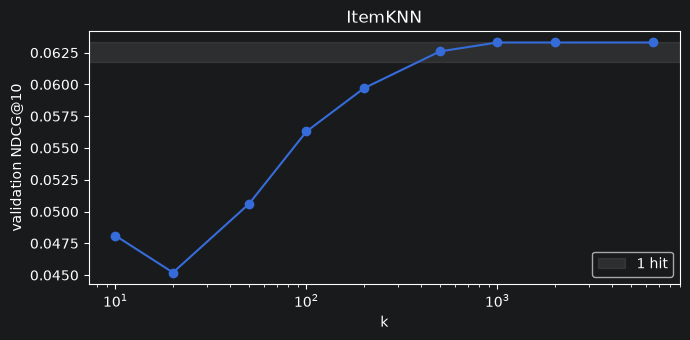

In [16]:
knn_grid = [10, 20, 50, 100, 200, 500, 1000, 2000, n_items]
knn_search = pd.DataFrame([{"k": k, **evaluate(ImplicitItemKNN(k).fit(P_train), val_target, seen_train)} for k in knn_grid])

best_knn = {"k": int(knn_search.loc[knn_search["ndcg@10"].idxmax(), "k"])}
print("лучший:", best_knn)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(knn_search["k"], knn_search["ndcg@10"], marker="o")
ax.axhspan(knn_search["ndcg@10"].max() - one_hit, knn_search["ndcg@10"].max(), color="gray", alpha=0.2, label="1 hit")
ax.set(xscale="log", xlabel="k", ylabel="validation NDCG@10", title="ItemKNN")
ax.legend()
plt.tight_layout()

knn_search

Качество растёт с $k$ и выходит на плато к $k = 1000$: дальше соседей с ненулевым сходством уже почти нет. На малых $k$ ItemKNN слабый, потому что контакты редкие и у многих групп мало общих пользователей. Даже лучший вариант (NDCG@10 = 0.063) хуже Popularity на validation (0.069).

### 5.3 Test

In [17]:
run_test("ItemKNN", ImplicitItemKNN(**best_knn).fit(P_full), best_knn)

ItemKNN, test: {'recall@10': 0.164, 'ndcg@10': 0.1022}


## 6. iALS

Implicit ALS. Предпочтение $p_{ui} = 1$, если был контакт, иначе 0; уверенность $c_{ui} = 1 + \alpha p_{ui}$. Минимизируем

$$\sum_{u,i} c_{ui} \left(p_{ui} - x_u^\top y_i\right)^2 + \lambda \left(\sum_u \|x_u\|^2 + \sum_i \|y_i\|^2\right)$$

попеременно по $X$ и $Y$. При фиксированных $Y$ у каждого пользователя решение в закрытом виде:

$$x_u = \left(Y^\top Y + \alpha Y_u^\top Y_u + \lambda I\right)^{-1} (1 + \alpha)\, Y_u^\top p_u,$$

где $Y_u$ — факторы групп, по которым у $u$ был контакт. Для групп так же. Скор — $x_u^\top y_i$.

### 6.1 Обучение с параметрами по умолчанию

In [18]:
als = ImplicitALS().fit(P_train)
evaluate(als, val_target, seen_train)

{'recall@10': 0.1786, 'ndcg@10': 0.1182}

### 6.2 Подбор гиперпараметров на validation

Параметров четыре, поэтому вместо сетки используем Optuna (TPE, `seed=42`, 60 запусков). Пространство поиска:

| параметр | диапазон |
|---|---|
| `n_factors` | 16–128, лог-шкала |
| `regularization` | 1e-3–1, лог-шкала |
| `alpha` | 1–100, лог-шкала |
| `n_iterations` | 5, 10, 15 |

лучший: {'n_factors': 41, 'regularization': 0.6915767546676903, 'alpha': 2.9244433929660576, 'n_iterations': 10} NDCG@10 = 0.1605


,number,alpha,n_factors,n_iterations,regularization,recall@10,ndcg@10
22,22,2.9244,41,10,0.6916,0.2443,0.1605
4,4,2.5081,41,10,0.2267,0.2412,0.1598
49,49,8.9997,33,10,0.3132,0.2260,0.1598
26,26,8.6795,33,10,0.5021,0.2260,0.1595
33,33,12.9095,33,10,0.1410,0.2290,0.1587
19,19,3.3772,24,10,0.7426,0.2382,0.1587
37,37,4.8514,63,10,0.7204,0.2366,0.1579
18,18,3.1334,24,10,0.0355,0.2366,0.1576
10,10,2.2636,43,10,0.0581,0.2275,0.1572
25,25,7.9500,48,10,0.9136,0.2351,0.1560


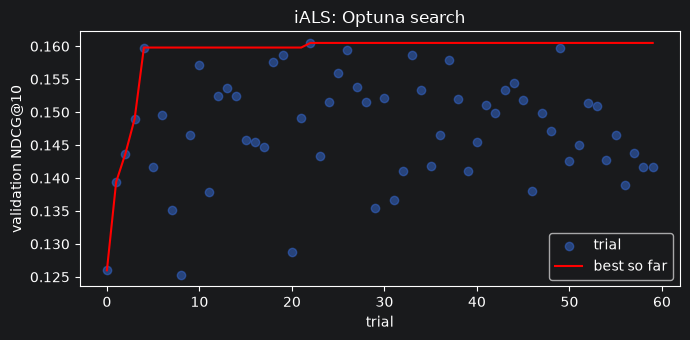

In [19]:
def als_objective(trial):
    params = {
        "n_factors": trial.suggest_int("n_factors", 16, 128, log=True),
        "regularization": trial.suggest_float("regularization", 1e-3, 1.0, log=True),
        "alpha": trial.suggest_float("alpha", 1.0, 100.0, log=True),
        "n_iterations": trial.suggest_categorical("n_iterations", [5, 10, 15]),
    }
    metrics = evaluate(ImplicitALS(**params).fit(P_train), val_target, seen_train)
    trial.set_user_attr("recall@10", metrics["recall@10"])
    return metrics["ndcg@10"]


als_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
als_study.optimize(als_objective, n_trials=60)
best_als = als_study.best_params
print("лучший:", best_als, "NDCG@10 =", round(als_study.best_value, 4))

als_trials = als_study.trials_dataframe(attrs=("number", "params", "user_attrs", "value"))
als_trials.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in als_trials.columns]
als_trials = als_trials.rename(columns={"value": "ndcg@10"})
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.scatter(als_trials["number"], als_trials["ndcg@10"], alpha=0.5, label="trial")
ax.plot(als_trials["number"], als_trials["ndcg@10"].cummax(), color="red", label="best so far")
ax.set(xlabel="trial", ylabel="validation NDCG@10", title="iALS: Optuna search")
ax.legend()
plt.tight_layout()

als_trials.sort_values("ndcg@10", ascending=False).head(10).round(4)

Подбор поднял NDCG@10 с 0.118 (параметры по умолчанию) до 0.161. Лучшие запуски сходятся к небольшому `alpha` (2–13) и 24–63 факторам, у всех десяти лучших `n_iterations = 10`.

### 6.3 Test

In [20]:
run_test("iALS", ImplicitALS(**best_als).fit(P_full), best_als)

iALS, test: {'recall@10': 0.2791, 'ndcg@10': 0.2026}


## 7. EASE

EASE — линейная item-item модель без скрытого слоя. Ищем матрицу весов $B$ с нулевой диагональю:

$$\min_B \|P - PB\|_F^2 + \lambda \|B\|_F^2, \quad \text{diag}(B) = 0$$

Решение в закрытом виде: $G = P^\top P + \lambda I$, $\hat B = I - G^{-1} \cdot \text{diagMat}(1 / \text{diag}(G^{-1}))$. Скор — $p_u^\top B$. Единственный гиперпараметр — $\lambda$ (`l2`).

### 7.1 Обучение с параметрами по умолчанию

In [21]:
ease = EASE().fit(P_train)
evaluate(ease, val_target, seen_train)

{'recall@10': 0.2519, 'ndcg@10': 0.1653}

### 7.2 Подбор l2 на validation

лучший: {'l2': 200.0}


,l2,recall@10,ndcg@10
0,5,0.2107,0.1479
1,10,0.2275,0.1556
2,20,0.2443,0.1654
3,50,0.2473,0.1671
4,100,0.2550,0.1667
5,200,0.2565,0.1689
6,500,0.2519,0.1653
7,1000,0.2504,0.1656


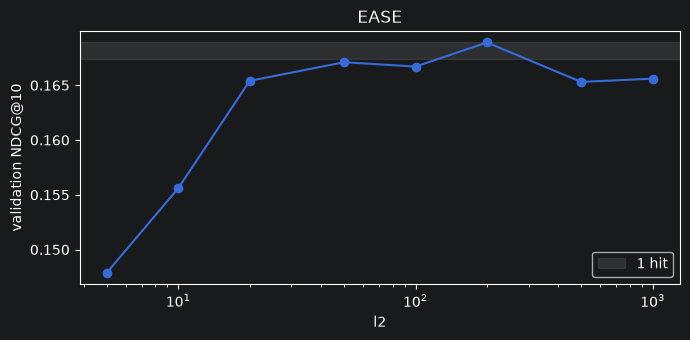

In [22]:
ease_grid = [5, 10, 20, 50, 100, 200, 500, 1000]
ease_search = pd.DataFrame([{"l2": l2, **evaluate(EASE(l2).fit(P_train), val_target, seen_train)} for l2 in ease_grid])

best_ease = {"l2": float(ease_search.loc[ease_search["ndcg@10"].idxmax(), "l2"])}
print("лучший:", best_ease)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(ease_search["l2"], ease_search["ndcg@10"], marker="o")
ax.axhspan(ease_search["ndcg@10"].max() - one_hit, ease_search["ndcg@10"].max(), color="gray", alpha=0.2, label="1 hit")
ax.set(xscale="log", xlabel="l2", ylabel="validation NDCG@10", title="EASE")
ax.legend()
plt.tight_layout()

ease_search

Кривая очень пологая: от `l2 = 20` до `l2 = 1000` NDCG@10 меняется в пределах 0.0035, это примерно 2 попадания. Лучший `l2 = 200` теперь внутри сетки, а не на её краю. Только при сильно маленькой регуляризации (5–10) качество заметно падает.

### 7.3 Test

In [23]:
run_test("EASE", EASE(**best_ease).fit(P_full), best_ease)

EASE, test: {'recall@10': 0.3133, 'ndcg@10': 0.2293}


## 8. Факторизационная машина

FM второго порядка. Вход — разреженный вектор $x$ из one-hot признаков пары:

$$\hat y(x) = w_0 + \sum_j w_j x_j + \sum_{j < l} \langle v_j, v_l \rangle x_j x_l$$

Признаки: id пользователя, id группы, категория группы, локация, корзина по числу объявлений в группе. Все признаки описывают группу и известны в момент рекомендации. Категорию берём, потому что доля контактов сильно различается между категориями. Число объявлений бьём на 5 квантильных корзин: с фиксированными границами почти все группы падали в одну корзину.

Обучение: положительные примеры — контакты из train, на каждый сэмплируем `negative_ratio` групп, которые пользователь не видел. Лосс — бинарная кросс-энтропия, оптимизатор Adam.

In [24]:
meta = item_metadata.assign(item_idx=item_metadata["item_id"].map(item_index)).dropna(subset=["item_idx"])
meta = meta.set_index(meta["item_idx"].astype(int)).sort_index()
meta["listing_bin"] = pd.qcut(meta["listing_count"], 5, labels=False, duplicates="drop")
item_features = np.column_stack([
    pd.factorize(meta[col], sort=True)[0] for col in ["category", "location", "listing_bin"]
])
print("групп с признаками:", len(meta), "из", n_items)
print("значений признаков:", item_features.max(axis=0) + 1)

групп с признаками: 6536 из 6536
значений признаков: [ 51 138   5]


### 8.1 Обучение с параметрами по умолчанию

In [25]:
fm = FMRecommender(random_state=SEED).fit(P_train, seen_train, item_features)
print("loss по эпохам:", np.round(fm.loss_history, 4))
evaluate(fm, val_target, seen_train)

loss по эпохам: [0.6766 0.6104 0.5358 0.4986 0.469 ]


{'recall@10': 0.0672, 'ndcg@10': 0.0347}

### 8.2 Подбор гиперпараметров на validation

Optuna (TPE, `seed=42`, 50 запусков). Пространство поиска:

| параметр | диапазон |
|---|---|
| `n_factors` | 8–128, лог-шкала |
| `learning_rate` | 1e-3–1e-1, лог-шкала |
| `weight_decay` | 1e-7–1e-3, лог-шкала |
| `negative_ratio` | 1–10 |
| `n_epochs` | 10, 20, 40 |

лучший: {'n_factors': 127, 'learning_rate': 0.011263226490895357, 'weight_decay': 7.551821970822969e-07, 'negative_ratio': 10, 'n_epochs': 40} NDCG@10 = 0.1748


,number,learning_rate,n_epochs,n_factors,negative_ratio,weight_decay,recall@10,ndcg@10
49,49,0.0113,40,127,10,0.0,0.2718,0.1748
25,25,0.0217,40,109,7,0.0,0.2519,0.1744
47,47,0.0078,40,120,10,0.0,0.2794,0.1722
35,35,0.0077,40,116,10,0.0,0.2672,0.1709
48,48,0.0068,40,124,10,0.0,0.2672,0.1700
40,40,0.0034,40,124,9,0.0,0.2656,0.1679
42,42,0.0049,40,98,10,0.0,0.2718,0.1662
46,46,0.0188,40,125,8,0.0,0.2565,0.1659
33,33,0.0019,40,128,10,0.0,0.2763,0.1655
15,15,0.0061,40,108,6,0.0,0.2748,0.1647


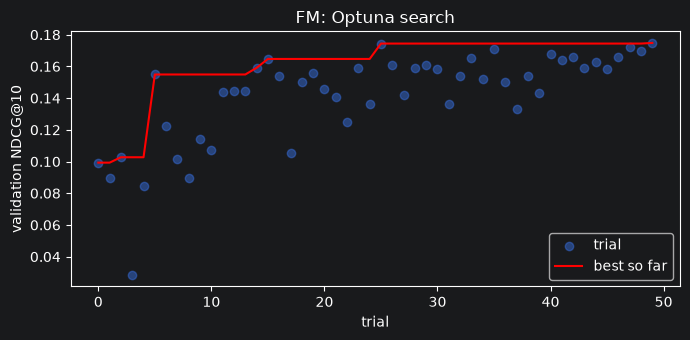

In [26]:
def fm_objective(trial):
    params = {
        "n_factors": trial.suggest_int("n_factors", 8, 128, log=True),
        "learning_rate": trial.suggest_float("learning_rate", 1e-3, 1e-1, log=True),
        "weight_decay": trial.suggest_float("weight_decay", 1e-7, 1e-3, log=True),
        "negative_ratio": trial.suggest_int("negative_ratio", 1, 10),
        "n_epochs": trial.suggest_categorical("n_epochs", [10, 20, 40]),
    }
    model = FMRecommender(**params, random_state=SEED).fit(P_train, seen_train, item_features)
    metrics = evaluate(model, val_target, seen_train)
    trial.set_user_attr("recall@10", metrics["recall@10"])
    return metrics["ndcg@10"]


fm_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
fm_study.optimize(fm_objective, n_trials=50)
best_fm = fm_study.best_params
print("лучший:", best_fm, "NDCG@10 =", round(fm_study.best_value, 4))

fm_trials = fm_study.trials_dataframe(attrs=("number", "params", "user_attrs", "value"))
fm_trials.columns = [c.replace("params_", "").replace("user_attrs_", "") for c in fm_trials.columns]
fm_trials = fm_trials.rename(columns={"value": "ndcg@10"})
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.scatter(fm_trials["number"], fm_trials["ndcg@10"], alpha=0.5, label="trial")
ax.plot(fm_trials["number"], fm_trials["ndcg@10"].cummax(), color="red", label="best so far")
ax.set(xlabel="trial", ylabel="validation NDCG@10", title="FM: Optuna search")
ax.legend()
plt.tight_layout()

fm_trials.sort_values("ndcg@10", ascending=False).head(10).round(4)

С параметрами по умолчанию FM почти не работает (NDCG@10 = 0.035): 5 эпох и 16 факторов слишком мало. После подбора — 0.175, лучшее значение на validation среди всех моделей. Почти все лучшие запуски выбирают 40 эпох, много факторов и много негативов (`negative_ratio` 7–10), то есть FM всё ещё упирается в верхние границы пространства поиска и, скорее всего, может стать ещё лучше при более долгом обучении.

### 8.3 Test

In [27]:
fm_final = FMRecommender(**best_fm, random_state=SEED).fit(P_full, seen_full, item_features)
run_test("FM", fm_final, best_fm)

FM, test: {'recall@10': 0.3146, 'ndcg@10': 0.2198}


## 9. ALS с кастомным таргетом

Базовый iALS считает все контакты одинаково важными, хотя контакт месячной давности хуже говорит о текущем интересе, чем вчерашний. Поэтому вместо бинарного $p_{ui}$ подаём в ALS сигнал, который затухает со временем:

$$r_{ui} = \text{clip}\left(\frac{\text{rating}_{ui} - 3}{2},\ 0,\ 1\right) \cdot \exp\left(-\ln 2 \cdot \frac{\text{age}_{ui}}{\text{half\_life}}\right),$$

где $\text{age}_{ui}$ — сколько дней прошло от пары до конца обучающих данных. Первый множитель равен 1 для контакта и 0 для просмотра, второй вдвое уменьшает вес каждые `half_life` дней. Дальше всё как в iALS: $c_{ui} = 1 + \alpha r_{ui}$, те же формулы обновления.

Чтобы сравнение было честным, `n_factors`, `regularization`, `alpha` и `n_iterations` берём от лучшего iALS и подбираем только `half_life`. Разбиение, кандидаты и критерий релевантности на test те же: целевой сигнал меняется только при обучении.

### 9.1 Обучение с параметрами по умолчанию

In [28]:
custom = CustomTargetALS(half_life=30.0, **best_als).fit(train, (n_users, n_items))
evaluate(custom, val_target, seen_train)

{'recall@10': 0.2519, 'ndcg@10': 0.1711}

### 9.2 Подбор half_life на validation

лучший half_life: 14.0


,half_life,recall@10,ndcg@10
0,3,0.1939,0.1391
1,7,0.2443,0.1654
2,14,0.2473,0.1712
3,21,0.2504,0.1703
4,30,0.2519,0.1711
5,45,0.2427,0.1662
6,60,0.2412,0.1638
7,90,0.2351,0.1622


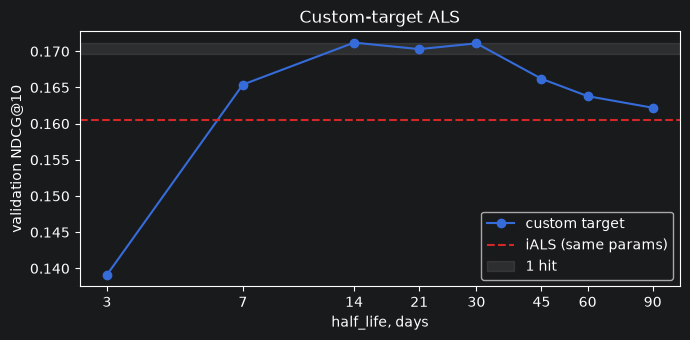

In [29]:
half_life_grid = [3, 7, 14, 21, 30, 45, 60, 90]
custom_search = pd.DataFrame([
    {"half_life": h, **evaluate(CustomTargetALS(half_life=h, **best_als).fit(train, (n_users, n_items)), val_target, seen_train)}
    for h in half_life_grid
])

best_custom = {"half_life": float(custom_search.loc[custom_search["ndcg@10"].idxmax(), "half_life"]), **best_als}
print("лучший half_life:", best_custom["half_life"])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(custom_search["half_life"], custom_search["ndcg@10"], marker="o", label="custom target")
ax.axhline(als_study.best_value, color="tab:red", linestyle="--", label="iALS (same params)")
ax.axhspan(custom_search["ndcg@10"].max() - one_hit, custom_search["ndcg@10"].max(), color="gray", alpha=0.2, label="1 hit")
ax.set(xscale="log", xlabel="half_life, days", ylabel="validation NDCG@10", title="Custom-target ALS")
ax.set_xticks(half_life_grid, labels=[str(h) for h in half_life_grid])
ax.minorticks_off()
ax.legend()
plt.tight_layout()

custom_search

При совсем коротком `half_life` (3 дня) старые контакты почти обнуляются и качество падает. При длинном (60–90 дней) затухания почти нет, и модель приближается к обычному iALS. Лучший диапазон — 14–30 дней, лучший `half_life = 14`. На validation кастомный таргет даёт 0.171 против 0.161 у iALS с теми же параметрами.

### 9.3 Test и сравнение с iALS

Custom-target ALS, test: {'recall@10': 0.2999, 'ndcg@10': 0.2219}


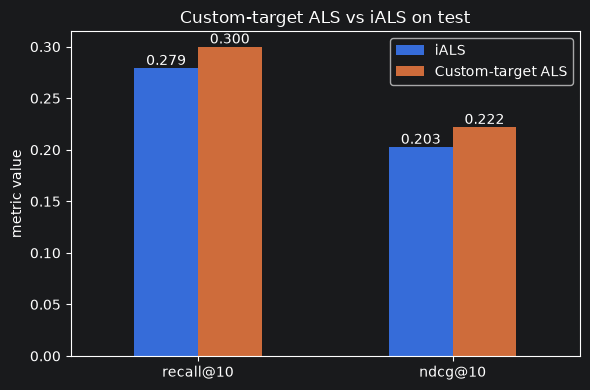

In [30]:
custom_final = CustomTargetALS(**best_custom).fit(train_full, (n_users, n_items))
run_test("Custom-target ALS", custom_final, best_custom)

pair = pd.DataFrame({
    name: {"recall@10": test_results[name]["recall@10"], "ndcg@10": test_results[name]["ndcg@10"]}
    for name in ["iALS", "Custom-target ALS"]
})
ax = pair.plot.bar(rot=0, figsize=(6, 4), title="Custom-target ALS vs iALS on test")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f")
plt.ylabel("metric value")
plt.tight_layout()

## 10. Итоговое сравнение на test

Общая таблица: метрики на test и выбранные на validation гиперпараметры.

In [31]:
def fmt_params(params):
    return ", ".join(f"{k}={v:.3g}" if isinstance(v, float) else f"{k}={v}" for k, v in params.items()) or "—"

comparison = pd.DataFrame([
    {"model": name, "hyperparameters": fmt_params(res["params"]), "recall@10": res["recall@10"], "ndcg@10": res["ndcg@10"]}
    for name, res in test_results.items()
]).sort_values("ndcg@10", ascending=False, ignore_index=True)
pd.set_option("display.max_colwidth", None)
comparison

,model,hyperparameters,recall@10,ndcg@10
0,EASE,l2=200,0.3133,0.2293
1,Custom-target ALS,"half_life=14, n_factors=41, regularization=0.692, alpha=2.92, n_iterations=10",0.2999,0.2219
2,FM,"n_factors=127, learning_rate=0.0113, weight_decay=7.55e-07, negative_ratio=10, n_epochs=40",0.3146,0.2198
3,iALS,"n_factors=41, regularization=0.692, alpha=2.92, n_iterations=10",0.2791,0.2026
4,ItemKNN,k=1000,0.1640,0.1022
5,Popularity,—,0.1395,0.0867


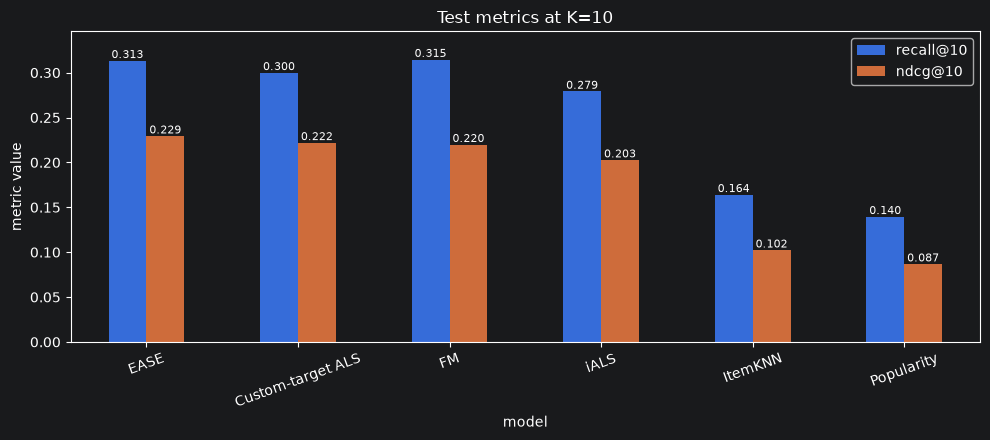

In [32]:
ax = comparison.plot.bar(x="model", y=["recall@10", "ndcg@10"], rot=20, figsize=(10, 4.5), title="Test metrics at K=10")
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=8)
ax.margins(y=0.1)
plt.ylabel("metric value")
plt.tight_layout()

## 11. Выводы

 Тройка лидеров: EASE, Custom-target ALS и FM, NDCG@10 на test 0.22–0.23, различия между ними в пределах нескольких попаданий. Потом идёт iALS (0.203), далеко позади ItemKNN (0.102) и Popularity (0.087). Если выбирать одну модель, то EASE: лучший результат, один гиперпараметр, к которому модель почти не чувствительна.

**Кастомный таргет iALS.** Затухание веса контакта с полупериодом 14 дней улучшило iALS на test с 0.203 до 0.222 NDCG@10, и преимущество видно и на validation, и на test. Остальные параметры и протокол не менялись, так что эффект даёт именно таргет: свежие контакты лучше предсказывают следующий.

**Метаданные в FM.** FM с категорией, локацией и корзиной числа объявлений дотягивает до уровня лидеров, но для этого нужны много факторов, 40 эпох и много негативов. Отдельно вклад метаданных мы не измеряли (FM без признаков не обучали), поэтому сказать, сколько дают именно признаки, нельзя.

**ItemKNN.** Самый слабый из персональных методов. Косинусное сходство по редким контактам слишком шумное.